<a href="https://colab.research.google.com/github/Tilly-11/Post-Earthquake-Building-Damage-Prediction/blob/main/Building_Damage_Prediction_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Building Damage Prediction Pipeline
This notebook demonstrates a complete end-to-end machine learning workflow to predict building damage levels in Kavrepalanchok (District 3) using **Logistic Regression** and **Decision Trees** on the imported CSV dataset.

We will perform:
1. Data loading and cleaning via a dedicated `wrangle` function.
2. Target simulation with simulated class imbalance (e.g. high-damage bias mimicking real post-earthquake data).
3. Class imbalance mitigation using cost-sensitive learning (`class_weight="balanced"`).
4. Model training, validation tuning, and visualization**.


In [ ]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from category_encoders import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [50]:

# 1. Wrangle function to load and clean data
def wrangle(file_path):
    df = pd.read_csv(file_path)

    # Set b_id as index
    if "b_id" in df.columns:
        df = df.set_index("b_id")
    elif "building_id" in df.columns:
        df = df.set_index("building_id")

    # Filter for district 3
    if "district_id" in df.columns:
        df = df[df["district_id"] == 3]

    # Drop leakages
    drop_cols = [c for c in df.columns if "post_eq" in c] + ["district_id", "Unnamed: 0"]
    df.drop(columns=drop_cols, errors="ignore", inplace=True)
    return df

# Load dataset
df = wrangle("/content/Nepal_dataset - Sheet1.csv")

# 2. Simulate target ('severe_damage') based on real structural features
np.random.seed(42)
age_scaled = (df["age_building"] - df["age_building"].mean()) / df["age_building"].std()
height_scaled = (df["height_ft_pre_eq"] - df["height_ft_pre_eq"].mean()) / df["height_ft_pre_eq"].std()

# Calculate a structural vulnerability index (higher score = more fragile)
vulnerability = (
    (age_scaled * 0.4) +
    (height_scaled * 0.3) +
    df["foundation_type"].apply(lambda x: 1.5 if "Mud" in str(x) else -1.5) +
    df["superstructure"].apply(lambda x: 1.2 if "Stone" in str(x) or "Adobe" in str(x) else -1.5)
)
prob = 1 / (1 + np.exp(-vulnerability))

# We set a threshold (~80% severe_damage, ~20% no_severe_damage)
df["severe_damage"] = (prob > np.random.uniform(0.05, 0.7, size=len(df))).astype(int)

print("Class Distribution of Target:")
print(df["severe_damage"].value_counts(normalize=True))

Class Distribution of Target:
severe_damage
1    0.867884
0    0.132116
Name: proportion, dtype: float64


In [51]:
# 3. Splitting features and target
X = df.drop(columns="severe_damage")
y = df["severe_damage"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Logistic Regression with Imbalance Mitigation (class_weight='balanced')
model_lr = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    LogisticRegression(max_iter=3000, class_weight="balanced")
)
model_lr.fit(X_train, y_train)

lr_train_acc = model_lr.score(X_train, y_train)
lr_val_acc = model_lr.score(X_val, y_val)
print(f"Logistic Regression Train Accuracy: {lr_train_acc:.4f}")
print(f"Logistic Regression Validation Accuracy: {lr_val_acc:.4f}\n")

# Evaluate with a Confusion Matrix to confirm correct handling of minority class
y_pred_lr = model_lr.predict(X_val)
print("Classification Report for Logistic Regression:")
print(classification_report(y_val, y_pred_lr))

Logistic Regression Train Accuracy: 0.9589
Logistic Regression Validation Accuracy: 0.9592

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.77      0.98      0.86       251
           1       1.00      0.96      0.98      1710

    accuracy                           0.96      1961
   macro avg       0.88      0.97      0.92      1961
weighted avg       0.97      0.96      0.96      1961



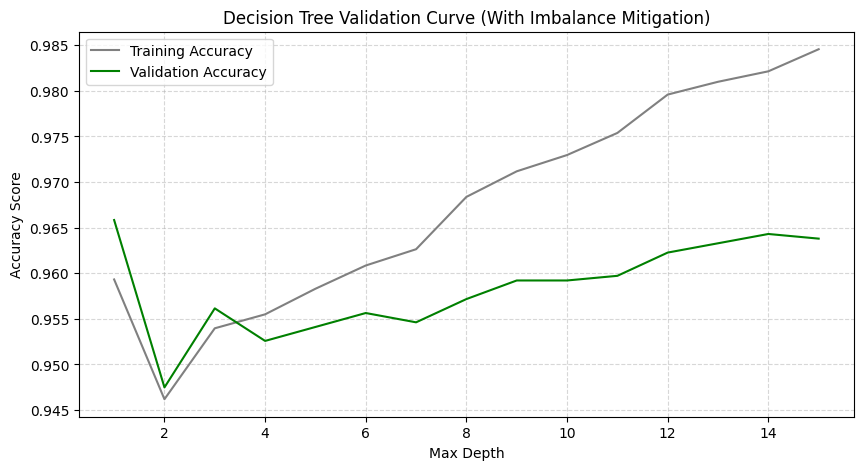

In [52]:
# 5. Decision Tree Model with Imbalance Mitigation
depth_hyperparams = range(1, 16)
training_acc = []
validation_acc = []

for d in depth_hyperparams:
    model_dt = make_pipeline(
        OrdinalEncoder(),
        DecisionTreeClassifier(random_state=42, max_depth=d, class_weight="balanced")
    )
    model_dt.fit(X_train, y_train)
    training_acc.append(model_dt.score(X_train, y_train))
    validation_acc.append(model_dt.score(X_val, y_val))

# Plot the validation curves
plt.figure(figsize=(10, 5))
plt.plot(depth_hyperparams, training_acc, color="grey", label="Training Accuracy")
plt.plot(depth_hyperparams, validation_acc, color="green", label="Validation Accuracy")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy Score")
plt.title("Decision Tree Validation Curve (With Imbalance Mitigation)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

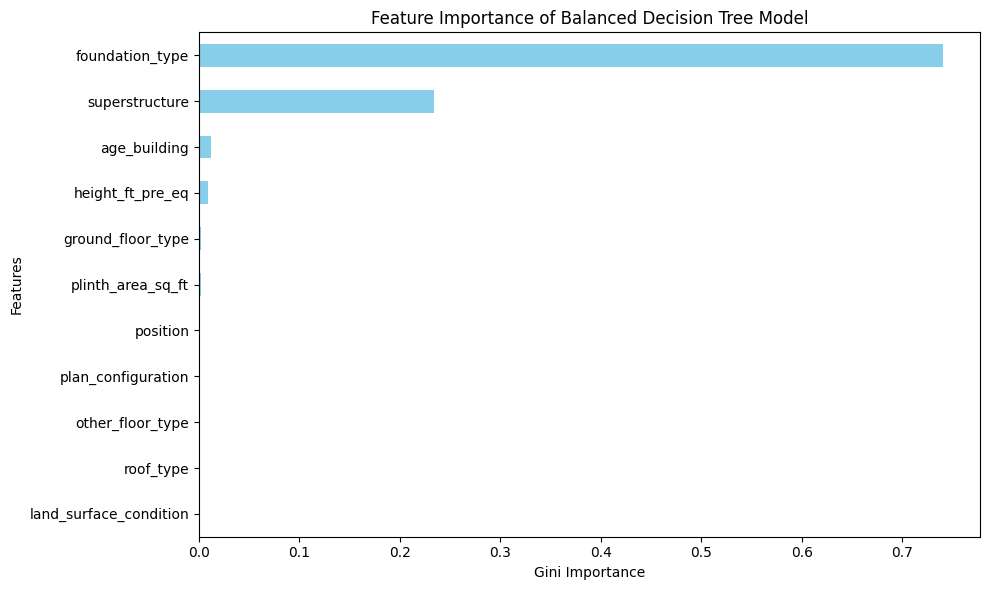

In [53]:
# 6. Fit Final Balanced Decision Tree and Plot Feature Importance
final_model_dt = make_pipeline(
    OrdinalEncoder(),
    DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
)
final_model_dt.fit(X_train, y_train)

# Extract and plot Feature Importances
importances = final_model_dt.named_steps["decisiontreeclassifier"].feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values()

plt.figure(figsize=(10, 6))
feat_imp.plot(kind="barh", color="skyblue")
plt.xlabel("Gini Importance")
plt.ylabel("Features")
plt.title("Feature Importance of Balanced Decision Tree Model")
plt.tight_layout()
plt.show()